# Checking labels from meta-labeling and trend scans

This native Julia companion retains the original public minute records, strict event and barrier crossing rules, supplied-side construction, and trend-scan horizons. Explicit time vectors replace pandas indexes. Changing thresholds are aligned to available volatility observations before accumulation. Random first-passage checks use a local Xoshiro generator with seed 11; its draws differ from NumPy and are saved for independent replay. Figures use the requested dark theme, and outputs are saved under `outputs/julia`.

Once a side is supplied, the binary label records whether that side produced a positive return by the event ending time:

$$
z_i=s_i\left(\log P_{\tau_i}-\log P_{t_i}\right),\qquad
m_i=\mathbf 1\{z_i>0\}.
$$

Here, $t_i$ and $\tau_i$ are event $i$ start and end times; $P_t$ is price; $s_i\in\{-1,1\}$ is the supplied side. $z_i$ is the side-adjusted log return; $m_i\in\{0,1\}$ is the meta-label; $\mathbf 1\{\cdot\}$ equals one when its condition is true.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("06_financial_labels");
using CSV, Printf
using RiskLabAI.Data: daily_volatility_with_log_returns,symmetric_cusum_filter,cusum_filter_events_dynamic_threshold,vertical_barrier,triple_barrier,meta_labeling,calculate_t_value_linear_regression,find_trend_using_trend_scanning
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
close_index,close_prices = raw.time,raw.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
violet = "#C084FC"

function count_histogram!(figure,values,bins;color,label=false,alpha=.75)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    counts = [count(value->edges[index]<=value && (value<edges[index+1] || index==bins && value==edges[end]),values) for index in 1:bins]
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,counts;bar_width=diff(edges),color,fillalpha=alpha,linecolor=color,label)
    ylims!(figure,0.,1.1max(maximum(counts),last(ylims(figure))))
    return DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts)
end

function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
span = 100
volatility = daily_volatility_with_log_returns(close_index,close_prices;span)
volatility_lookup = Dict(zip(volatility.index,volatility.volatility))

function dynamic_threshold_events(multiplier)
    selected = findall(isfinite,volatility.volatility)
    positions = [price_positions[volatility.index[index]] for index in selected]
    aligned = vcat(first(positions)-1,positions)
    return cusum_filter_events_dynamic_threshold(close_index[aligned],log_price[aligned],vcat(NaN,multiplier.*volatility.volatility[selected]))
end
event_times = dynamic_threshold_events(2.)
final_times = vertical_barrier(close_index,event_times,1)
final_lookup = Dict(zip(final_times.event,final_times.barrier))
event_times = [time for time in event_times if haskey(final_lookup,time) && isfinite(get(volatility_lookup,time,NaN))];
event_times = [time for time in event_times if price_positions[time]>60 && log_price[price_positions[time]]!=log_price[price_positions[time]-60]]
sides = [sign(log_price[price_positions[time]]-log_price[price_positions[time]-60]) for time in event_times];


## Binary Meta-Labels

In [2]:
side_events = DataFrame(event_start=event_times,end_time=[final_lookup[time] for time in event_times],base_width=[volatility_lookup[time] for time in event_times],side=sides)
completed = copy(side_events)
completed.end_time = triple_barrier(close_index,close_prices,side_events,(1.,1.))
meta_labels = meta_labeling(completed,close_index,close_prices)
meta_rows = NamedTuple[]
for label in sort(unique(meta_labels.label))
    values = meta_labels.ret[meta_labels.label.==label]
    push!(meta_rows,(;label,events=length(values),middle=median(values),average=mean(values),share=length(values)/nrow(meta_labels)))
end
meta_summary = DataFrame(meta_rows)
rename!(meta_summary,["Meta-label","Events","Middle signed log return","Mean signed log return","Share"])
save_table(meta_summary,paths,"meta_label_summary";caption="Binary outcomes after applying a side chosen from the preceding hour.",label="tab:meta-label-summary")
save_data(side_events,paths,"supplied_side_events")
save_data(completed,paths,"completed_side_events")
save_data(meta_labels,paths,"meta_labels");


Row,Meta-label,Events,Middle signed log return,Mean signed log return,Share
,Float64,Int64,Float64,Float64,Float64
1,0.0,240,-0.0101402,-0.0113158,0.456274
2,1.0,286,0.0100457,0.0114634,0.543726


## Rare-Label Check

A label is retained only when its observed share reaches the chosen minimum share:

$$
\widehat p_{\ell}=\frac{n_{\ell}}{n},\qquad
\mathcal L_{\eta}=\{\ell:\widehat p_{\ell}\geq\eta\}.
$$

Here, $\ell$ is a label; $n_{\ell}$ is its event count; $n$ is the total event count. $\widehat p_{\ell}$ is the observed share of label $\ell$; $\eta\in[0,1]$ is the minimum share; $\mathcal L_{\eta}$ is the retained label set.

Row,Data,Label,Count before,Share before,Count after,Retained
,String,Float64,Int64,Float64,Int64,String
1,Public meta-labels,0.0,240,0.456274,240,Yes
2,Public meta-labels,1.0,286,0.543726,286,Yes
3,Controlled labels,-1.0,4,0.04,0,No
4,Controlled labels,0.0,21,0.21,21,Yes
5,Controlled labels,1.0,75,0.75,75,Yes


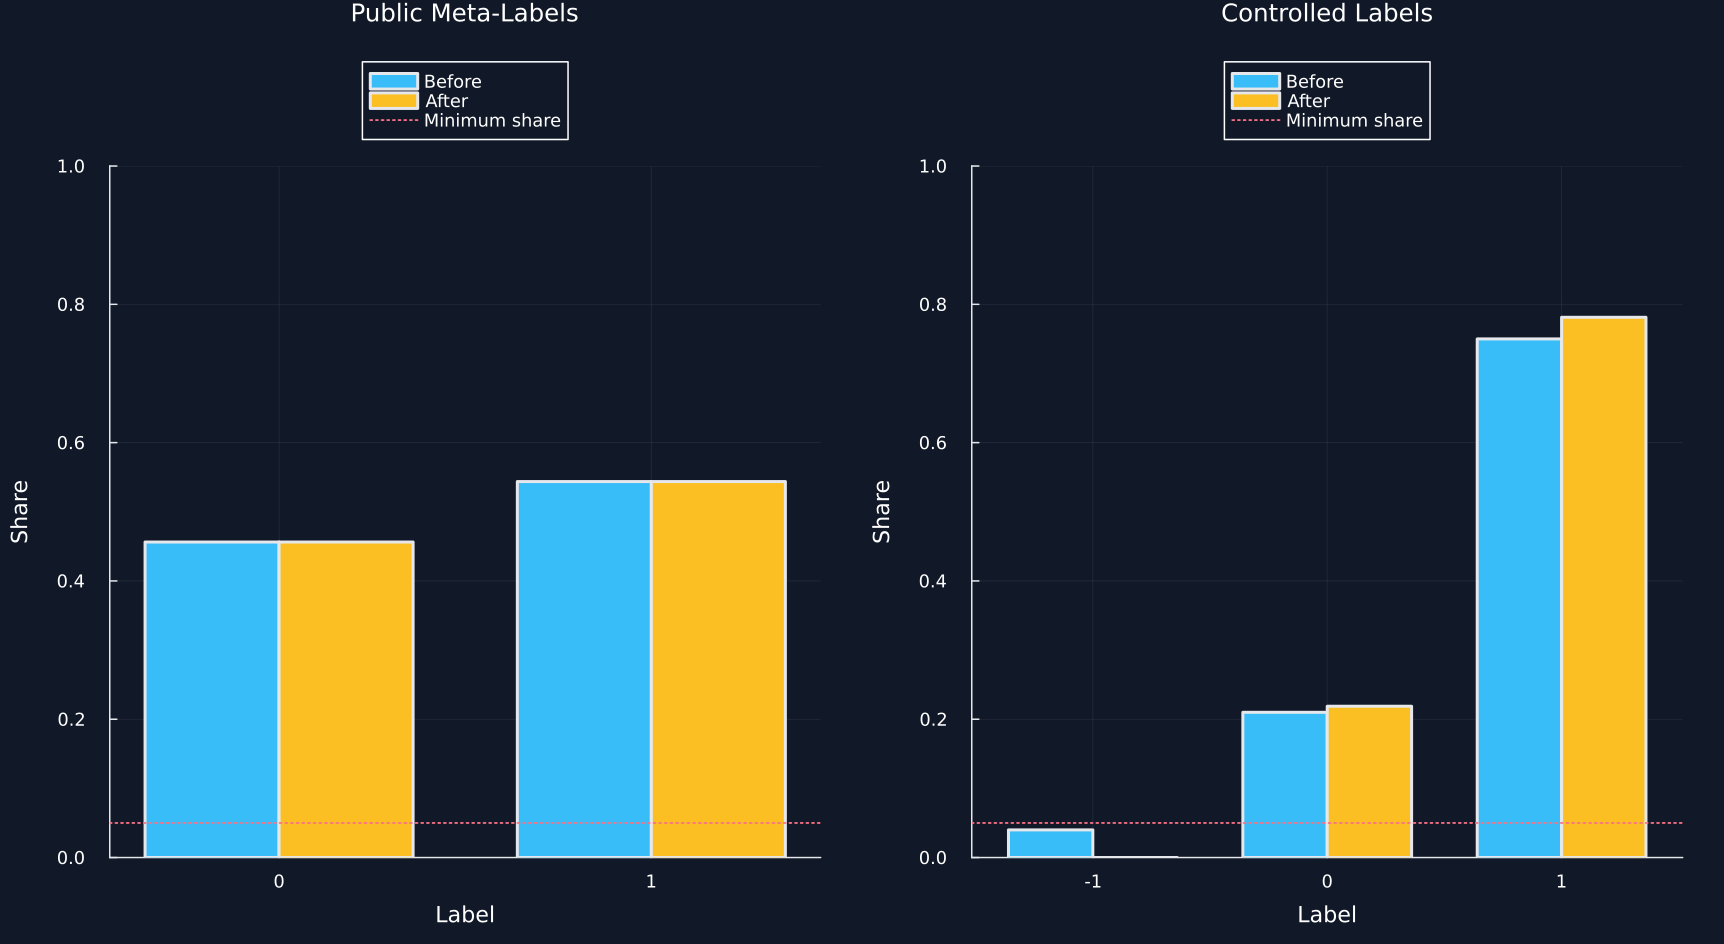

In [3]:
function filter_rare_labels(frame,label_column,minimum_share)
    labels = frame[!,label_column]
    retained = [label for label in unique(labels) if count(==(label),labels)/length(labels)>=minimum_share]
    return frame[in.(labels,Ref(retained)),:]
end
minimum_share = .05
public_label_frame = select(meta_labels,:label)
controlled_label_frame = DataFrame(label=vcat(fill(-1.,4),fill(0.,21),fill(1.,75)))
public_filtered = filter_rare_labels(public_label_frame,:label,minimum_share)
controlled_filtered = filter_rare_labels(controlled_label_frame,:label,minimum_share)
rare_rows = NamedTuple[]
panels = []
for (dataset_name,title,before,after) in [("Public meta-labels","Public Meta-Labels",public_label_frame,public_filtered),("Controlled labels","Controlled Labels",controlled_label_frame,controlled_filtered)]
    labels_seen = sort(unique(before.label))
    for label in labels_seen
        before_count,after_count = count(==(label),before.label),count(==(label),after.label)
        push!(rare_rows,(;data=dataset_name,label,before=before_count,share=before_count/nrow(before),after=after_count,retained=after_count>0 ? "Yes" : "No"))
    end
    positions = collect(eachindex(labels_seen))
    before_share = [count(==(label),before.label)/nrow(before) for label in labels_seen]
    after_share = [count(==(label),after.label)/nrow(after) for label in labels_seen]
    panel = bar(positions.-.18,before_share;bar_width=.36,color=palette.cyan,label="Before",xticks=(positions,string.(Int.(labels_seen))),xlabel="Label",ylabel="Share",title,legend=:outertop,ylims=(0.,1.))
    bar!(panel,positions.+.18,after_share;bar_width=.36,color=palette.amber,label="After")
    hline!(panel,[minimum_share];color=palette.rose,linestyle=:dot,linewidth=1.2,label="Minimum share")
    push!(panels,panel)
end
rare_label_summary = DataFrame(rare_rows)
rename!(rare_label_summary,["Data","Label","Count before","Share before","Count after","Retained"])
save_table(rare_label_summary,paths,"rare_label_summary";caption="A five-percent rare-label rule applied to public and controlled labels.",label="tab:chapter5-rare-labels")
save_figure(plot(panels...;layout=(1,2),size=(1150,630)),paths,"rare_label_filtering")


## Trend Scanning

For each event and each forward length, a straight line is fitted to price and the slope is measured relative to its estimated uncertainty:

$$
P_{t_i+j}=\beta_{0,i,L}+\beta_{1,i,L}j+\varepsilon_{i,j},\qquad
T_{i,L}=\frac{\widehat\beta_{1,i,L}}{\operatorname{SE}(\widehat\beta_{1,i,L})}.
$$

Here, $t_i$ is event $i$ start; $j=0,\ldots,L-1$ counts observations; $L$ is a candidate forward length. $\beta_{0,i,L}$ is the intercept; $\beta_{1,i,L}$ is the slope; $\varepsilon_{i,j}$ is the residual; $T_{i,L}$ is the slope t-value. $\widehat\beta_{1,i,L}$ is the fitted slope and $\operatorname{SE}(\widehat\beta_{1,i,L})$ is its standard error.

The selected length has the strongest absolute linear trend, and its sign becomes the trend label:

$$
L_i^*=\arg\max_{L\in\mathcal L}|T_{i,L}|,\qquad
q_i=\operatorname{sign}(T_{i,L_i^*}).
$$

Here, $\mathcal L$ is the chosen set of forward lengths; $L_i^*$ is the selected length for event $i.$ $T_{i,L}$ is the slope t-value for length $L$; $q_i\in\{-1,0,1\}$ is the trend label; $\arg\max$ selects the largest absolute t-value.

In [4]:
candidate_events = completed.event_start[1:min(240,nrow(completed))]
span = (12,73)
trends = find_trend_using_trend_scanning(candidate_events,close_index,close_prices,span)
best_records,candidate_rows = NamedTuple[],NamedTuple[]
for start in trends.event_start
    location = price_positions[start]
    values = [(length,calculate_t_value_linear_regression(close_prices[location:location+length-1])) for length in span[1]:span[2]-1]
    finite_values = filter(pair->isfinite(last(pair)),values)
    best_length,best_value = isempty(finite_values) ? first(values) : finite_values[argmax(abs.(last.(finite_values)))]
    push!(best_records,(;event_start=start,selected_length=best_length,independent_t_value=best_value))
    append!(candidate_rows,[(;event_start=start,length,t_value) for (length,t_value) in values])
end
trend_results = innerjoin(trends,DataFrame(best_records);on=:event_start)
sort!(trend_results,:event_start)
trend_results.absolute_t_value = abs.(trend_results.t_value)
trend_rows = NamedTuple[]
for label in sort(unique(trend_results.trend))
    part = trend_results[trend_results.trend.==label,:]
    push!(trend_rows,(;label,events=nrow(part),length=median(part.selected_length),strength=median(part.absolute_t_value),share=nrow(part)/nrow(trend_results)))
end
trend_summary = DataFrame(trend_rows)
rename!(trend_summary,["Trend label","Events","Middle selected length","Middle absolute t-value","Share"])
save_table(trend_summary,paths,"trend_label_summary";caption="Trend labels, selected forward lengths, and t-value magnitudes.",label="tab:trend-label-summary")
save_data(trend_results,paths,"trend_results")
save_data(DataFrame(candidate_rows),paths,"trend_candidate_t_values");


Row,Trend label,Events,Middle selected length,Middle absolute t-value,Share
,Float64,Int64,Float64,Float64,Float64
1,-1.0,112,49.0,9.81461,0.466667
2,1.0,128,54.5,11.6149,0.533333


## Label Checks

Row,Meta-label,Trend disagrees with side,Trend agrees with side
,Float64,Int64,Int64
1,0.0,88,19
2,1.0,30,103


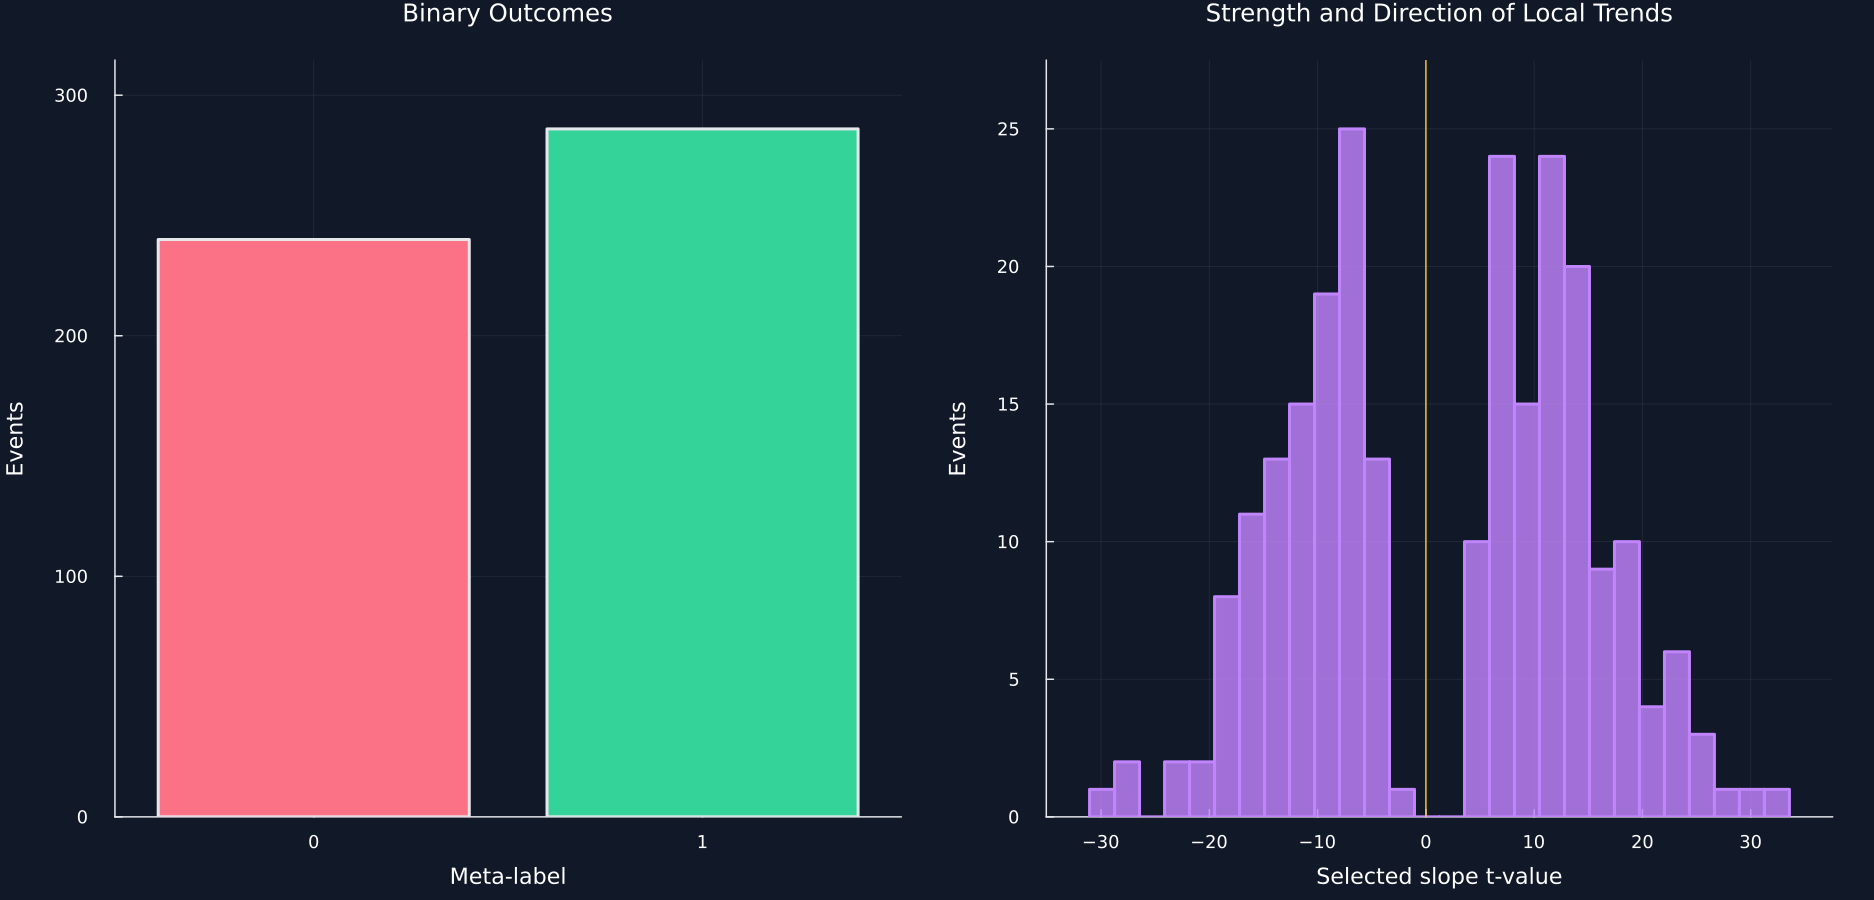

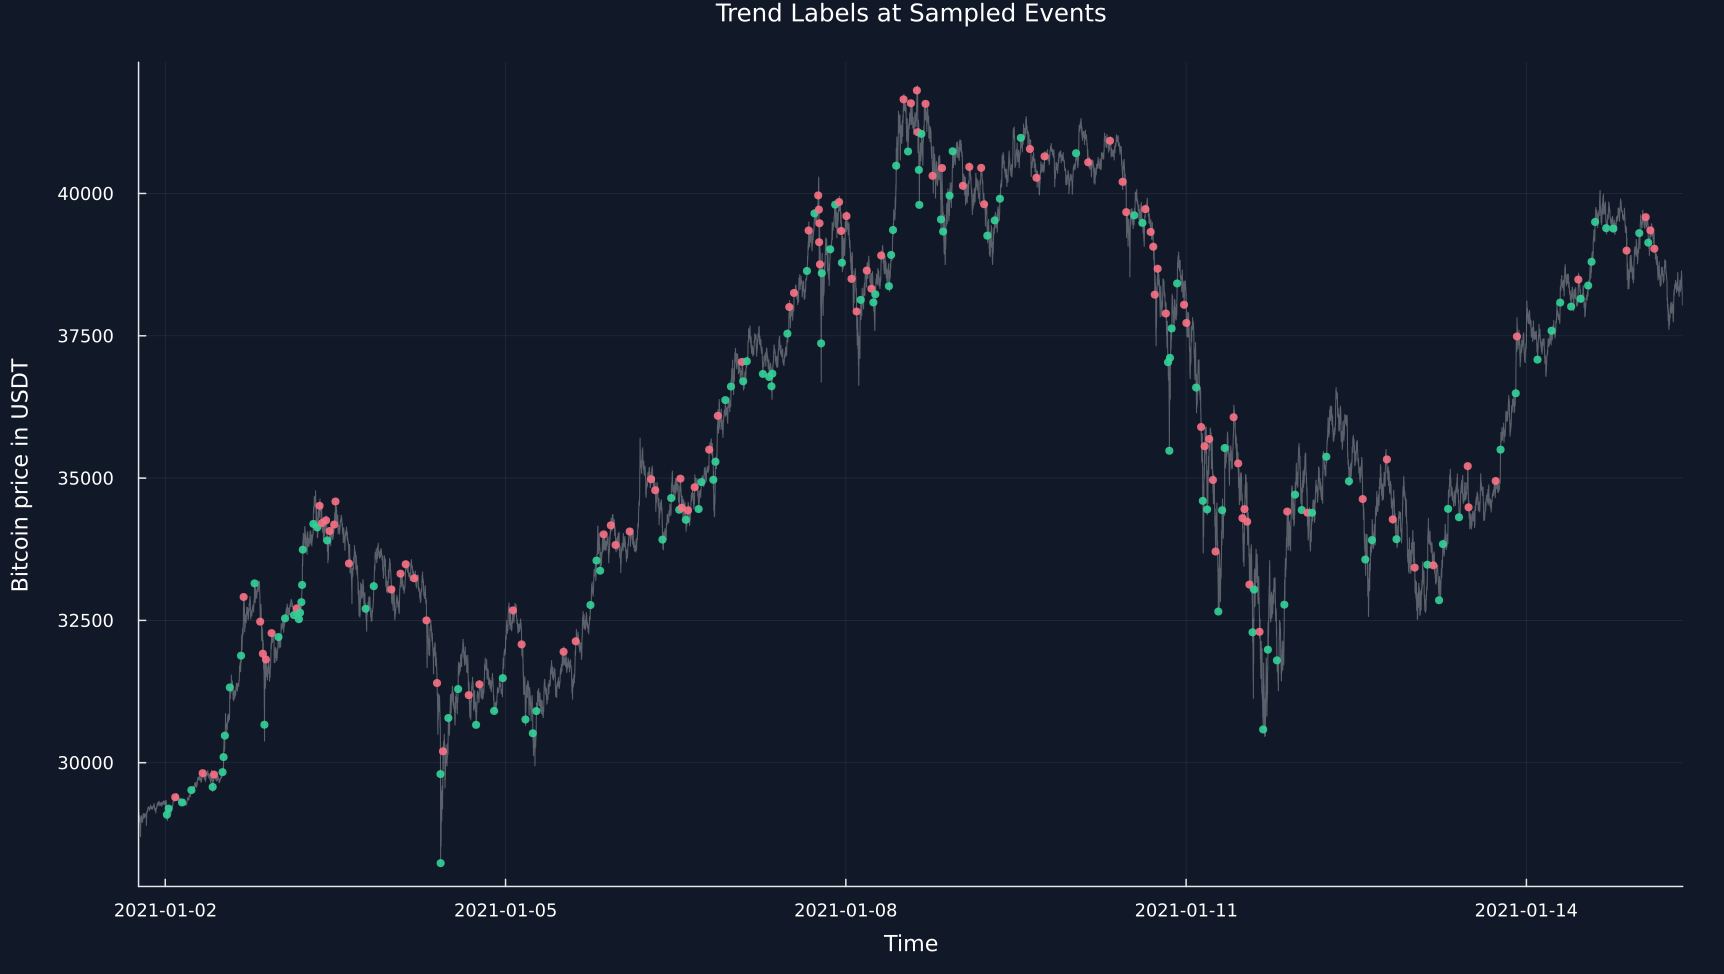

In [5]:
common = innerjoin(meta_labels,select(trend_results,:event_start,:trend,:selected_length,:t_value);on=:event_start)
comparison_rows = NamedTuple[]
for label in sort(unique(common.label))
    part = common[common.label.==label,:]
    agrees = count(part.trend.==part.side)
    push!(comparison_rows,(;label,disagrees=nrow(part)-agrees,agrees))
end
comparison = DataFrame(comparison_rows)
rename!(comparison,["Meta-label","Trend disagrees with side","Trend agrees with side"])
save_table(comparison,paths,"label_comparison";caption="Meta-label outcomes compared with the direction of the selected local trend.",label="tab:label-comparison")
label_values = sort(unique(meta_labels.label))
label_counts = [count(==(label),meta_labels.label) for label in label_values]
p1 = bar(string.(Int.(label_values)),label_counts;color=[palette.rose,palette.green][1:length(label_values)],xlabel="Meta-label",ylabel="Events",title="Binary Outcomes",legend=false,ylims=(0.,1.1maximum(label_counts)))
p2 = plot(;xlabel="Selected slope t-value",ylabel="Events",title="Strength and Direction of Local Trends",legend=false)
histogram_data = count_histogram!(p2,trend_results.t_value,28;color=violet,alpha=.82)
vline!(p2,[0.];color=palette.amber,linewidth=1.,label=false)
save_data(histogram_data,paths,"trend_t_value_histogram")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,600)),paths,"label_distributions")
trend_view_start,trend_view_end = minimum(trend_results.event_start)-Hour(6),maximum(trend_results.event_start)+Hour(6)
view_positions = findall(trend_view_start .<= close_index .<= trend_view_end)
figure = plot(close_index[view_positions],close_prices[view_positions];color=palette.text,alpha=.35,linewidth=.7,xlabel="Time",ylabel="Bitcoin price in USDT",title="Trend Labels at Sampled Events",legend=false,size=(1150,650))
scatter!(figure,trend_results.event_start,[close_prices[price_positions[time]] for time in trend_results.event_start];markercolor=ifelse.(trend_results.trend.>0,palette.green,palette.rose),markersize=3,alpha=.9,markerstrokewidth=0)
xlims!(figure,Dates.value(trend_view_start),Dates.value(trend_view_end))
save_figure(figure,paths,"trend_scanning_labels")


## Tests

In [6]:
@assert calculate_t_value_linear_regression([1.,2.,3.,4.,5.]) == Inf
@assert calculate_t_value_linear_regression([5.,4.,3.,2.,1.]) == -Inf
@assert isnan(calculate_t_value_linear_regression(fill(2.,5)))
@assert issubset(Set(meta_labels.label),Set([0.,1.]))
@assert issubset(Set(trend_results.trend),Set([-1.,0.,1.]))
@assert nrow(meta_labels)>0
@assert nrow(trend_results)>0
@assert all(in([-1.,1.]),completed.side)
@assert isapprox(trend_results.t_value,trend_results.independent_t_value;rtol=1e-10,atol=1e-10)
@assert all(span[1] .<= trend_results.selected_length .< span[2])
@assert sum(meta_summary.Events)==nrow(meta_labels)
@assert sum(trend_summary.Events)==nrow(trend_results)
@assert sum(Matrix(comparison[:,2:3]))==nrow(common)
@assert isapprox(sum(meta_summary.Share),1.)
@assert isapprox(sum(trend_summary.Share),1.)
@assert nrow(public_filtered)==nrow(public_label_frame)
@assert nrow(controlled_filtered)==96
@assert -1. ∉ controlled_filtered.label
@assert only(rare_label_summary.Retained[(rare_label_summary.Data.=="Controlled labels").&(rare_label_summary.Label.==-1)])=="No"
@assert isfile(joinpath(paths.figures,"rare_label_filtering.pdf"))
@assert isfile(joinpath(paths.tables,"rare_label_summary.tex"))
